In [1]:
"""
Notebook for python plots for E3ME

"""
 
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import seaborn as sns
from scipy.stats import gaussian_kde

In [2]:
# ── Paths ─────────────────────────────────────────────────────────────────────

script_dir = os.getcwd()
wd = os.path.dirname(os.path.dirname(script_dir))
os.chdir(wd)

config_path = "Emulation/code/config/config.json"
with open(config_path) as f:
    config = json.load(f)

data_path = "Emulation\\data\\"
output_dir = os.path.join(data_path, "predictions")
figures_dir = os.path.join(data_path, "figures")
os.makedirs(figures_dir, exist_ok=True)

In [3]:
os.getcwd()


'c:\\Users\\ib400\\Github\\rebound_emulation'

In [4]:
gbl_preds = "preds_combined_fac.csv"
df_gbl = pd.read_csv(os.path.join(output_dir, gbl_preds))

# list cols where rebound vars are obsolete due to no rebound switch
cols = ['trans_rebound', 'heat_rebound']
df_gbl.loc[df_gbl['emulator'].str.contains('No_RB', na=False), cols] = np.nan

# Remove mixed scenarios (where one turnover is high and the other low) to reduce size
df = df_gbl[df_gbl['combined'].str.contains('Mixed', na=False) == False]
df.head()

C:\Users\ib400\AppData\Local\Temp\ipykernel_26348\2793673916.py:2: DtypeWarning: Columns (0: pw_transition_tri, 1: reb_turn_tri) have mixed types. Specify dtype option on import or set low_memory=False.
  df_gbl = pd.read_csv(os.path.join(output_dir, gbl_preds))


,cr_wind,cr_solar,lead_onshore,lead_offshore,lead_solar,heat_rebound,trans_rebound,heat_turnover,trans_turnover,prediction,emulator,id,sample_id,pw_transition_tri,pw_transition,rebound,turnover,combined,reb_turn_tri
2,0.0,0.0,0.0,0.5,0.0,0.105773,0.252641,0.803242,0.718641,26839.360492,em_Diff_EngDem_PJ,id_1,3,Fast transition,Fast transition,Low rebound,High turnover,Low rebound - High turnover,NaN
4,0.0,0.0,0.0,0.5,0.0,0.608356,0.566673,0.068971,0.091524,30266.683760,em_Diff_EngDem_PJ,id_1,5,Fast transition,Fast transition,Mid rebound,Low turnover,Mid rebound - Low turnover,NaN
16,0.0,0.0,0.0,0.5,0.0,0.151561,0.270743,0.151061,0.163984,22449.037868,em_Diff_EngDem_PJ,id_1,17,Fast transition,Fast transition,Low rebound,Low turnover,Low rebound - Low turnover,NaN
20,0.0,0.0,0.0,0.5,0.0,0.816880,0.675980,0.663137,0.800446,37892.398435,em_Diff_EngDem_PJ,id_1,21,Fast transition,Fast transition,High rebound,High turnover,High rebound - High turnover,NaN
41,0.0,0.0,0.0,0.5,0.0,0.347765,0.617492,0.696992,0.843021,36699.946123,em_Diff_EngDem_PJ,id_1,42,Fast transition,Fast transition,Mid rebound,High turnover,Mid rebound - High turnover,NaN


In [5]:
# # ── Policy factor helper ───────────────────────────────────────────────────────

# def add_policy_factors(df: pd.DataFrame) -> pd.DataFrame:
#     df = df.copy()

#     # reb_level_tri
#     conditions = [
#         df["reb_switch"] == 0,
#         (df["reb_switch"] == 1) & (df["heat_rebound"] == 0) & (df["trans_rebound"] == 0),
#         (df["reb_switch"] == 1) & (df["heat_rebound"] == 1) & (df["trans_rebound"] == 1),
#     ]
#     choices = ["no rebound", "low rebound", "high rebound"]
#     df["reb_level_tri"] = pd.Categorical(
#         np.select(conditions, choices, default=np.nan),
#         categories=["no rebound", "low rebound", "high rebound"],
#         ordered=True,
#     )

#     # reb_active
#     df["reb_active"] = pd.Categorical(
#         np.where(df["reb_switch"] == 0, "no rebound", "rebound"),
#         categories=["no rebound", "rebound"],
#         ordered=True,
#     )

#     # turn_level_bi
#     cond_turn_bi = [
#         (df["trans_turnover"] == 0) & (df["heat_turnover"] == 0),
#         (df["trans_turnover"] == 1) & (df["heat_turnover"] == 1),
#     ]
#     df["turn_level_bi"] = pd.Categorical(
#         np.select(cond_turn_bi, ["low turnover", "high turnover"], default=np.nan),
#         categories=["low turnover", "high turnover"],
#         ordered=True,
#     )

#     # leads
#     cond_leads = [
#         (df["lead_solar"] < 0.5) & (df["lead_onshore"] < 0.5),
#         (df["lead_solar"] >= 0.5) & (df["lead_onshore"] >= 0.5),
#     ]
#     df["leads"] = pd.Categorical(
#         np.select(cond_leads, ["Short tech lead", "Long tech lead"], default=np.nan),
#         categories=["Short tech lead", "Long tech lead"],
#         ordered=True,
#     )

#     # cr_total
#     cond_cr = [
#         (df["cr_wind"] < 0.5) & (df["cr_solar"] < 0.5),
#         (df["cr_solar"] >= 0.5) & (df["cr_wind"] >= 0.5),
#     ]
#     df["cr_total"] = pd.Categorical(
#         np.select(cond_cr, ["Low Cannibalisation", "High Cannibalisation"], default=np.nan),
#         categories=["Low Cannibalisation", "High Cannibalisation"],
#         ordered=True,
#     )

#     # turn_level
#     cond_turn = [
#         (df["trans_turnover"] < 0.5) & (df["heat_turnover"] < 0.5),
#         (df["trans_turnover"] >= 0.5) & (df["heat_turnover"] >= 0.5),
#     ]
#     df["turn_level"] = pd.Categorical(
#         np.select(cond_turn, ["low turnover", "high turnover"], default=np.nan),
#         categories=["low turnover", "high turnover"],
#         ordered=True,
#     )

#     # reb_level
#     cond_reb = [
#         (df["trans_rebound"] < 0.5) & (df["heat_rebound"] < 0.5),
#         (df["trans_rebound"] >= 0.5) & (df["heat_rebound"] >= 0.5),
#     ]
#     df["reb_level"] = pd.Categorical(
#         np.select(cond_reb, ["low rebound", "high rebound"], default=np.nan),
#         categories=["low rebound", "high rebound"],
#         ordered=True,
#     )

#     # power_transition (depends on cr_total and leads already set)
#     cond_pt = [
#         (df["cr_total"] == "High Cannibalisation") & (df["leads"] == "Long tech lead"),
#         (df["cr_total"] == "Low Cannibalisation") & (df["leads"] == "Short tech lead"),
#     ]
#     df["power_transition"] = pd.Categorical(
#         np.select(cond_pt, ["slow transition", "fast transition"], default=np.nan),
#         categories=["slow transition", "fast transition"],
#         ordered=True,
#     )

#     return df

## ── Apply factors ─────────────────────────────────────────────────────────────

#df_gbl = add_policy_factors(df_gbl)

In [6]:
# # Theme -----------------------------------------------------------------------

THEME = dict(
    title_fontsize=18,
    axis_title_fontsize=14,
    axis_tick_fontsize=12,
    strip_fontsize=13,
    legend_fontsize=12,
)

palette_viridis = sns.color_palette("magma", n_colors=9)

def apply_common_theme(ax):
    ax.set_xlabel(ax.get_xlabel(), fontsize=THEME["axis_title_fontsize"], fontweight="bold")
    ax.set_ylabel(ax.get_ylabel(), fontsize=THEME["axis_title_fontsize"], fontweight="bold")
    for label in ax.get_xticklabels():
        label.set_fontsize(THEME["axis_tick_fontsize"])
        label.set_fontweight("bold")
        label.set_rotation(45)
        label.set_ha("right")
    for label in ax.get_yticklabels():
        label.set_fontsize(THEME["axis_tick_fontsize"])

In [ ]:
df = df_gbl[df_gbl['combined'].str.contains('Mixed', na=False) == False]


In [7]:
pw_levels = df["pw_transition_tri"].dropna().unique()
pw_levels = pw_levels[0] #[0, 2]]
ems = ['em_No_RB_GtCO2', 'em_RB_GtCO2']
combinations = [ 'Low rebound - Low turnover', 'High rebound - High turnover']

df = df[df['emulator'].isin(ems)]
df = df[df['combined'].isin(combinations)]
df = df[df['pw_transition_tri'] == "Fast transition"]
df = df[df['reb_turn_tri'].isna()]

In [ ]:
summary_statssummary_stats = (
    df.groupby(["combined"], observed=True)["prediction"]
    .mean()
    .reset_index()
    .rename(columns={"prediction": "mean_pred"})
)

In [ ]:
df

,cr_wind,cr_solar,lead_onshore,lead_offshore,lead_solar,heat_rebound,trans_rebound,heat_turnover,trans_turnover,prediction,emulator,id,sample_id,pw_transition_tri,pw_transition,rebound,turnover,combined,reb_turn_tri
300016,0.0,0.0,0.0,0.5,0.0,NaN,NaN,0.151061,0.163984,756.580204,em_No_RB_GtCO2,id_1,17,Fast transition,Fast transition,Low rebound,Low turnover,Low rebound - Low turnover,NaN
300020,0.0,0.0,0.0,0.5,0.0,NaN,NaN,0.663137,0.800446,740.294352,em_No_RB_GtCO2,id_1,21,Fast transition,Fast transition,High rebound,High turnover,High rebound - High turnover,NaN
300158,0.0,0.0,0.0,0.5,0.0,NaN,NaN,0.231496,0.211418,755.377557,em_No_RB_GtCO2,id_1,159,Fast transition,Fast transition,Low rebound,Low turnover,Low rebound - Low turnover,NaN
300163,0.0,0.0,0.0,0.5,0.0,NaN,NaN,0.747785,0.994906,735.262704,em_No_RB_GtCO2,id_1,164,Fast transition,Fast transition,High rebound,High turnover,High rebound - High turnover,NaN
300186,0.0,0.0,0.0,0.5,0.0,NaN,NaN,0.071838,0.311653,752.829947,em_No_RB_GtCO2,id_1,187,Fast transition,Fast transition,Low rebound,Low turnover,Low rebound - Low turnover,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
539850,1.0,1.0,1.0,0.5,1.0,0.769953,0.692600,0.830527,0.697154,875.381351,em_RB_GtCO2,id_3,19851,Slow transition,Slow transition,High rebound,High turnover,High rebound - High turnover,NaN
539923,1.0,1.0,1.0,0.5,1.0,0.147560,0.128712,0.089536,0.236584,874.808545,em_RB_GtCO2,id_3,19924,Slow transition,Slow transition,Low rebound,Low turnover,Low rebound - Low turnover,NaN
539948,1.0,1.0,1.0,0.5,1.0,0.017989,0.296401,0.143682,0.089209,877.524091,em_RB_GtCO2,id_3,19949,Slow transition,Slow transition,Low rebound,Low turnover,Low rebound - Low turnover,NaN
539987,1.0,1.0,1.0,0.5,1.0,0.264508,0.120272,0.270644,0.278437,874.364687,em_RB_GtCO2,id_3,19988,Slow transition,Slow transition,Low rebound,Low turnover,Low rebound - Low turnover,NaN


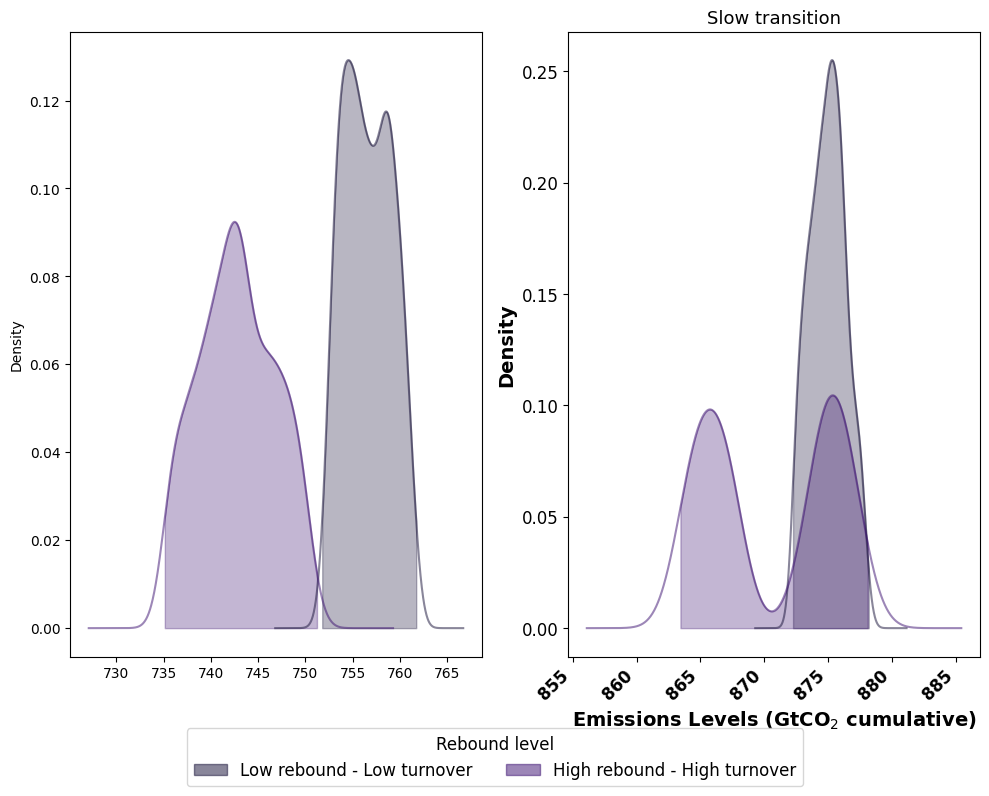

In [ ]:
fig, axes = plt.subplots(1, len(pw_levels), figsize=(10, 8), sharey=False)

for ax, tl in zip(axes, pw_levels):
    subset = df[df["pw_transition_tri"] == tl]
    for i, rl in enumerate(comb_levels):
        grp = subset[subset["combined"] == rl]["prediction"].dropna()
   
        grp.plot.kde(ax=ax, label=rl, color=palette_viridis[i], alpha=0.5)

        
        ax.fill_between(
            np.linspace(grp.min(), grp.max(), 200),
            gaussian_kde(grp)(np.linspace(grp.min(), grp.max(), 200)),
            alpha=0.3,
            color=palette_viridis[i],
        )
        vline_val = summary_stats.loc[
            (summary_stats["rebound"] == rl) & (summary_stats["turnover"] == tl),
            "mean_pred",
        ]
        if not vline_val.empty:
            ax.axvline(vline_val.values[0], color=palette_viridis[i], linestyle="--", linewidth=0.8)

ax.set_title(tl, fontsize=THEME["strip_fontsize"])
ax.set_xlabel(r"Emissions Levels (GtCO$_2$ cumulative)", fontsize=THEME["axis_title_fontsize"], fontweight="bold")
ax.set_ylabel("Density", fontsize=THEME["axis_title_fontsize"], fontweight="bold")
apply_common_theme(ax)

handles = [
    mpatches.Patch(color=palette_viridis[i], label=lbl, alpha=0.5)
    for i, lbl in enumerate(df["combined"].unique().tolist())
]
fig.legend(handles=handles, loc="lower center", ncol=2, fontsize=THEME["legend_fontsize"],
           title="Rebound level", title_fontsize=THEME["legend_fontsize"], bbox_to_anchor=(0.5, 0))
fig.tight_layout(rect=[0, 0.06, 1, 1])

In [ ]:
for i, lbl in enumerate(df["combined"].unique().tolist()):
    print(lbl)
    print(i)

Low rebound - High turnover
0
Mid rebound - Low turnover
1
Low rebound - Low turnover
2
High rebound - High turnover
3
Mid rebound - High turnover
4
Mid rebound - Mid turnover
5
High rebound - Low turnover
6
High rebound - Mid turnover
7
Low rebound - Mid turnover
8


<StringArray>
[ 'em_Diff_EngDem_PJ',        'em_Diff_GDP',      'em_Diff_GtCO2',
 'em_No_RB_EngDem_PJ',       'em_No_RB_GDP',     'em_No_RB_GtCO2',
    'em_RB_EngDem_PJ',          'em_RB_GDP',        'em_RB_GtCO2']
Length: 9, dtype: str

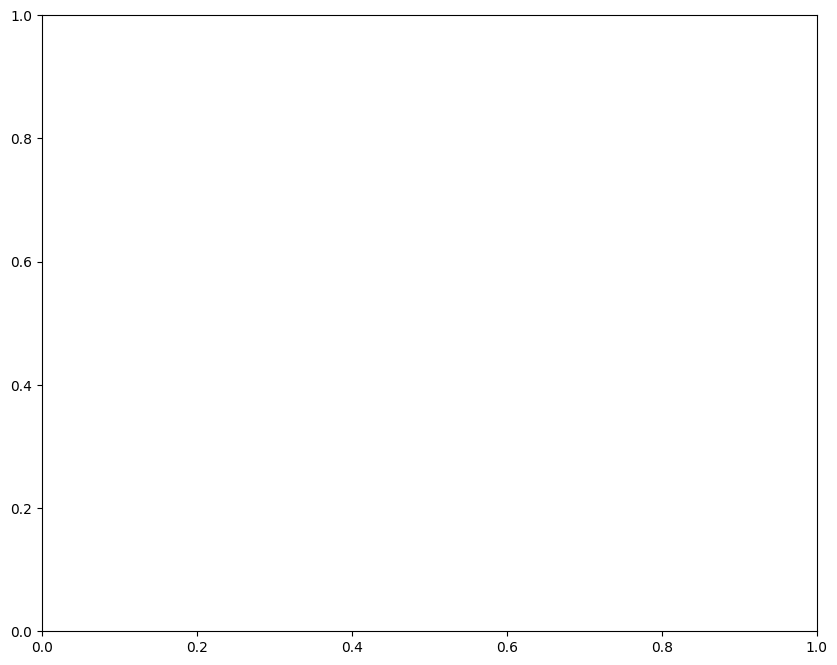

In [ ]:
fig, axes = plt.subplots(1, 1, figsize=(10, 8), sharey=False)

grp
# grp.plot.kde(ax=ax, label=rl, color=palette_viridis[i], alpha=0.5)  # draw the smooth density curve
# grp.plot.kde()  # draw the smooth density curve
df['emulator'].unique()

In [ ]:
turn_levels[0]


'High turnover'

In [ ]:
palette_viridis.

[(0.445163, 0.122724, 0.506901), (0.944006, 0.377643, 0.365136)]

In [ ]:
enumerate(df["rebound"].unique().tolist())

In [ ]:

fig.savefig(os.path.join(figures_dir, "emiss_gbl.png"), dpi=100)
plt.close(fig)
print("Saved emiss_gbl.png")
